Task 1: 

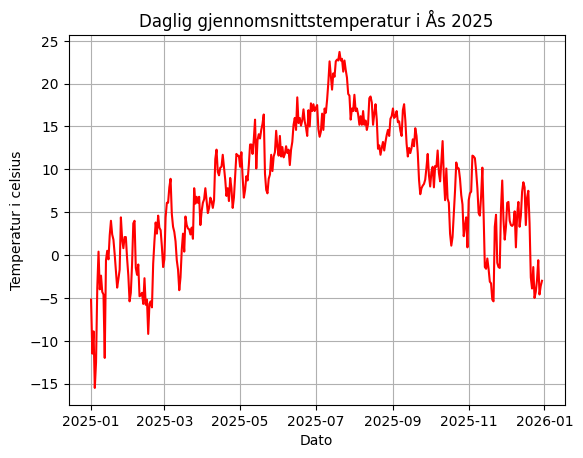

       Mean  Median   Min   Max
0  7.902747     8.4 -15.5  23.7


In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Henter client_id som er lagret utenfor REPO
with open('C:/Users/Selin/OneDrive/NMBU/2.år/INF201/Frost_API.txt', 'r') as infile:
    client_id = infile.read().strip()


def frost_request(client_id: str, sources: str, elements: str, referencetime: str) -> pd.DataFrame:
    '''
        Henter data fra Frost API og returnerer en pandas DataFrame
    
        Parameters:
            client_id (str): API-nøkkelen din fra frost.met.no
            sources (str): Stasjons-ID, f.eks. 'SN17850'
            elements (str): Element, f.eks. 'mean(air_temperature P1D)'
            referencetime (str): Tidsrom, f.eks. '2025-01-01/2025-12-31'
        Returnere:
            pd.DataFrame: DataFrame med dato og verdien til observasjonen som er angitt
        '''
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': sources,
        'elements': elements,
        'referencetime': referencetime,
    }

    r = requests.get(endpoint, params=parameters, auth=(client_id, ''))

    if r.status_code != 200:
        print(f'Feil {r.status_code}: {r.json()}')
        return None

    data = r.json()

    if 'data' not in data:
        print('Ingen data mottatt')
        return None

    records = []
    for item in data['data']:
        date = item['referenceTime']
        value = item['observations'][0]['value']
        records.append((date, value))

    df = pd.DataFrame(records, columns=['date', 'value'])
    df['date'] = pd.to_datetime(df['date'])

    return df


# Kaller funksjonen
df = frost_request(
    client_id=client_id,
    sources='SN17850',
    elements='mean(air_temperature P1D)',
    referencetime='2025-01-01/2025-12-31'
)

# plotter grafen
plt.plot(df['date'], df['value'], color='red')
plt.title('Daglig gjennomsnittstemperatur i Ås 2025')
plt.xlabel('Dato')
plt.ylabel('Temperatur i celsius')
plt.grid(True)
plt.show()

# Lager en oversiktlig tabell
summary = {
    'Mean': df['value'].mean(),
    'Median': df['value'].median(),
    'Min': df['value'].min(),
    'Max': df['value'].max(),
}

summary_df = pd.DataFrame(summary, index=[0])
print(summary_df)

Diskuter resultatene

Task 2:

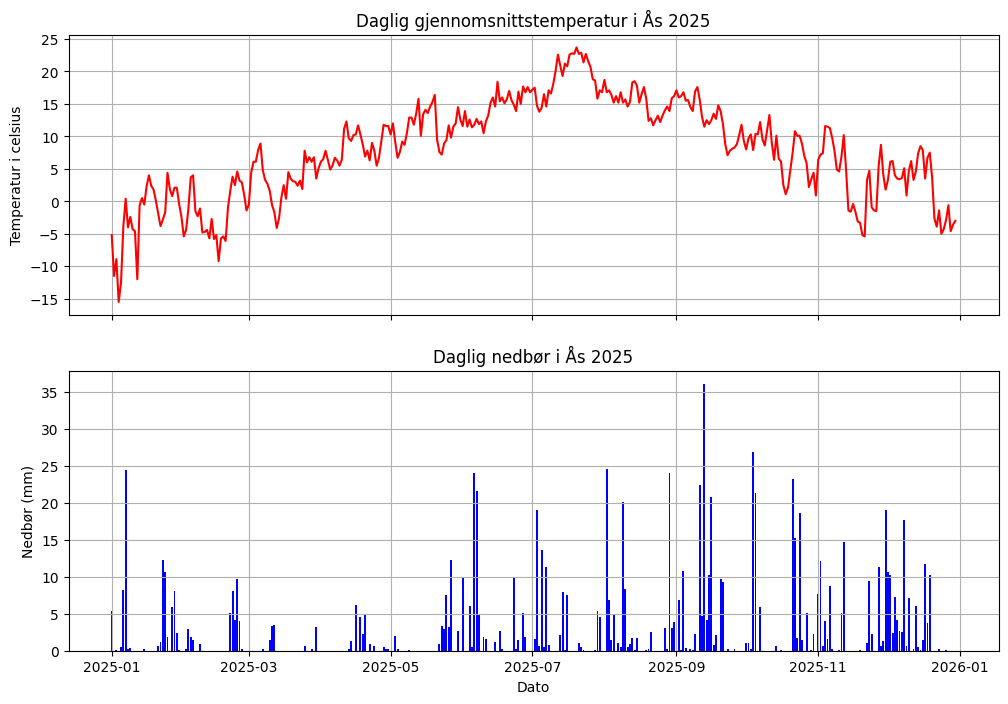

In [ ]:
df_temp = frost_request(
    client_id=client_id,
    sources="SN17850",
    elements="mean(air_temperature P1D)",
    referencetime="2025-01-01/2025-12-31"
)

df_rain = frost_request(
    client_id=client_id,
    sources="SN17850",
    elements="sum(precipitation_amount P1D)",
    referencetime="2025-01-01/2025-12-31"
)

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Temperatur
ax[0].plot(df_temp['date'], df_temp['value'], color='red')
ax[0].set_title('Daglig gjennomsnittstemperatur i Ås 2025')
ax[0].set_ylabel('Temperatur i celsius')
ax[0].grid(True)

# Nedbør
ax[1].bar(df_rain['date'], df_rain['value'], color='blue')
ax[1].set_title('Daglig nedbør i Ås 2025')
ax[1].set_ylabel('Nedbør (mm)')
ax[1].grid(True)

plt.xlabel('Dato')
plt.show()


diskutere resultatene her